<a href="https://colab.research.google.com/github/jukagoncalves/sistemas-inteligentes/blob/main/atividades/atividade-01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Verificar a variável de maior correlação com o consumo de cerveja e selecionar ela.

- Construir a reta de regressão achando Beta 1 e Beta 2

- Dizer qual o valor de R² (R-Square)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsRegressor


In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
dados = pd.read_csv('Consumo_cerveja.csv', sep = ';')
dados.describe()

,temp_media,temp_min,temp_max,chuva,fds,consumo
count,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,21.226356,17.461370,26.611507,5.196712,0.284932,25401.367123
std,3.180108,2.826185,4.317366,12.417844,0.452001,4399.142703
min,12.900000,10.600000,14.500000,0.000000,0.000000,14343.000000
25%,19.020000,15.300000,23.800000,0.000000,0.000000,22008.000000
50%,21.380000,17.900000,26.900000,0.000000,0.000000,24867.000000
75%,23.280000,19.600000,29.400000,3.200000,1.000000,28631.000000
max,28.860000,24.500000,36.500000,94.800000,1.000000,37937.000000


In [ ]:
dados.head()

,data,temp_media,temp_min,temp_max,chuva,fds,consumo
0,01/01/2015,27.30,23.9,32.5,0.0,0,25461
1,02/01/2015,27.02,24.5,33.5,0.0,0,28972
2,03/01/2015,24.82,22.4,29.9,0.0,1,30814
3,04/01/2015,23.98,21.5,28.6,1.2,1,29799
4,05/01/2015,23.82,21.0,28.3,0.0,0,28900


In [ ]:
#amostra =  dados.query('consumo<25000').sample(n=20, random_state=101)
amostra = dados

In [ ]:
amostra[['temp_media',	'temp_min',	'temp_max',	'chuva',	'fds',	'consumo']].cov()

,temp_media,temp_min,temp_max,chuva,fds,consumo
temp_media,10.113085,7.754043,12.665817,0.964180,-0.073025,8.038714e+03
temp_min,7.754043,7.987322,8.210858,3.461274,-0.076051,4.879979e+03
temp_max,12.665817,8.210858,18.639647,-2.643369,-0.078562,1.220609e+04
chuva,0.964180,3.461274,-2.643369,154.202846,0.008906,-1.058602e+04
fds,-0.073025,-0.076051,-0.078562,0.008906,0.204305,1.006101e+03
consumo,8038.714473,4879.979331,12206.090819,-10586.023240,1006.101152,1.935246e+07


# Descobrir váriavel de maior correlação

In [ ]:
correlacao = amostra[['temp_media', 'temp_min', 'temp_max', 'chuva', 'fds', 'consumo']].corr()['consumo']
display(correlacao)

,consumo
temp_media,0.574615
temp_min,0.392509
temp_max,0.642672
chuva,-0.193784
fds,0.505981
consumo,1.000000


# Reta de Regressão com Beta 1 e Beta 2

In [ ]:
x = amostra[['temp_max']]
y = amostra ['consumo']

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.20,
    random_state = 42
)

reg = LinearRegression()
reg.fit(x_train,y_train)

beta_1 = reg.intercept_
beta_2 = reg.coef_[0]

print(f'Beta 1: {beta_1:.4f}')
print(f'Beta 2: {beta_2:.4f}')


Beta 1: 8402.3844
Beta 2: 633.7668


# R² - Regressão

In [ ]:
pred = reg.predict(x_test)

r2 = r2_score(y_test, pred)

print(f'R²: {r2:.4f}')

R²: 0.3794


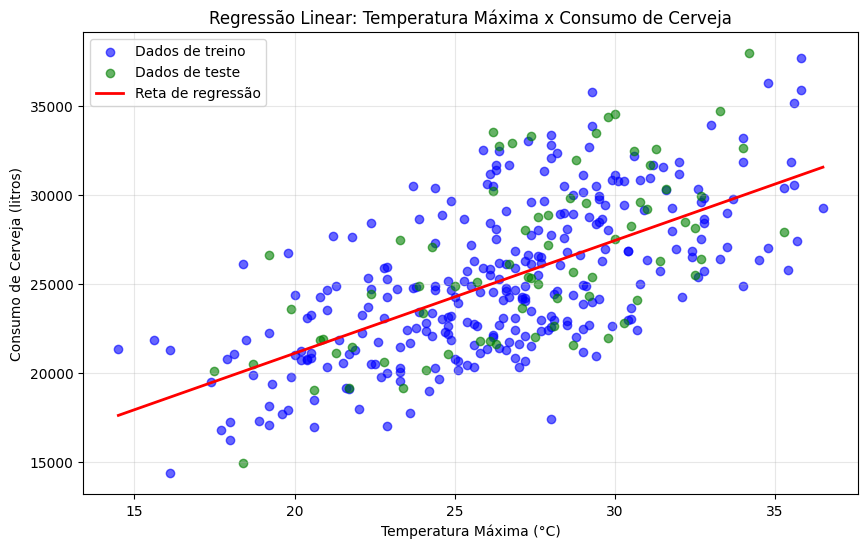

In [ ]:
# Previsões do modelo
y_pred_train = reg.predict(x_train)
y_pred_test = reg.predict(x_test)

# Gráfico
plt.figure(figsize=(10, 6))

# Pontos de treino e teste
plt.scatter(x_train, y_train, color='blue', alpha=0.6, label='Dados de treino')
plt.scatter(x_test, y_test, color='green', alpha=0.6, label='Dados de teste')

# Reta de regressão (ordenando os valores de x para a linha ficar contínua)
x_sorted = x.sort_values(by='temp_max')
y_line = reg.predict(x_sorted)
plt.plot(x_sorted, y_line, color='red', linewidth=2, label='Reta de regressão')

plt.xlabel('Temperatura Máxima (°C)')
plt.ylabel('Consumo de Cerveja (litros)')
plt.title('Regressão Linear: Temperatura Máxima x Consumo de Cerveja')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Modelo KNN

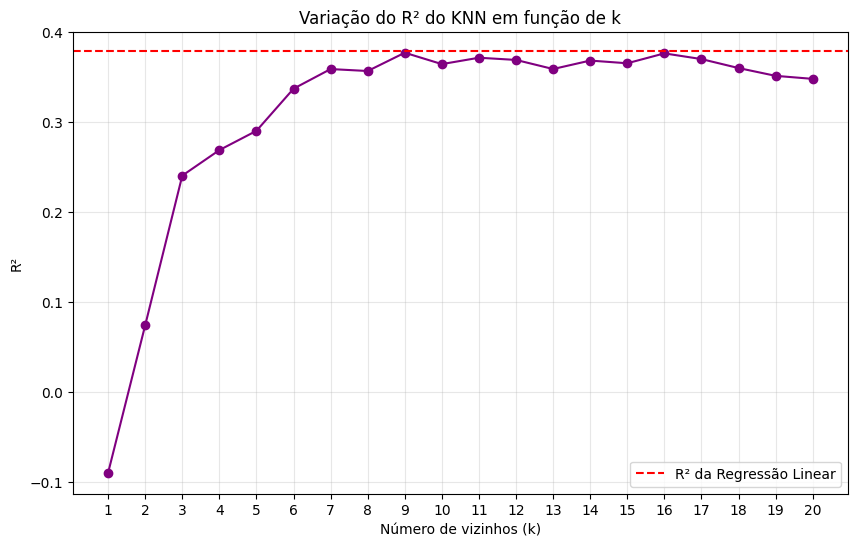

In [ ]:
# Testar diferentes valores de k
valores_k = range(1, 21)  # testando k de 1 até 20
r2_scores = []

for k in valores_k:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(x_train, y_train)
    pred = knn.predict(x_test)
    r2 = r2_score(y_test, pred)
    r2_scores.append(r2)

# Gráfico
plt.figure(figsize=(10, 6))
plt.plot(valores_k, r2_scores, marker='o', color='purple')
plt.axhline(y=0.3794, color='red', linestyle='--', label='R² da Regressão Linear')

plt.xlabel('Número de vizinhos (k)')
plt.ylabel('R²')
plt.title('Variação do R² do KNN em função de k')
plt.xticks(valores_k)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
knn = KNeighborsRegressor(n_neighbors = 9)
knn.fit(x_train, y_train)

KNeighborsRegressor(n_neighbors=9)

In [ ]:
pred = knn.predict(x_test)

r2 = r2_score(y_test, pred)

print(f'R²: {r2:.4f}')

R²: 0.3771
